In [39]:
import pandas as pd

df = pd.read_csv("newsSourcesSAMPLED100.csv", header=None)
df.columns = ['source', 'author', 'title', 'text', 'date']

#Čišćenje
for col in ['author', 'title', 'text', 'date']:
    df[col] = df[col].astype(str).str.replace(r'^Q1Z', '', regex=True)
df['date'] = df['date'].str.replace(r'Z1Q$', '', regex=True)

print(f"Ukupno vesti: {len(df)}")
df.head(10)

Ukupno vesti: 1400


,source,author,title,text,date
0,New York Times,Mitch Smith,Minnesota Officer Was ‘Reacting to the Presenc...,"ST. ANTHONY, Minn. — A lawyer for the subur...",2017-01-18
1,New York Times,Gia Kourlas,This City Ballet Dancer Has a New Role: Being ...,"Fairies can be so fickle. One night, all you w...",2017-02-13
2,New York Times,Jack Ewing,Some Early Signs of ‘Brexit’ Upheaval - The Ne...,FRANKFURT — Only hours after Britain decide...,2016-12-03
3,New York Times,Richard Pérez-Peña and Rachel Abrams,Trump Assails Nordstrom for ‘Unfairly’ Droppin...,WASHINGTON — President Trump lashed out on ...,2017-02-09
4,New York Times,Karen Zraick and Lisa Iaboni,"Michael Flynn, Kim Jong-un: Your Tuesday Eveni...",(Want to get this briefing by email? Here’s th...,2017-02-14
5,New York Times,Gia Kourlas,"At New York City Ballet, Lacing Up Their Sneak...",Justin Peck stops short of calling it a protes...,2017-01-27
6,New York Times,Matthew Rosenberg and Charlie Savage,"One Guantánamo Detainee Pleads for Release, bu...",WASHINGTON — Two longtime detainees at Guan...,2016-06-03
7,New York Times,"Thomas Fuller, Conor Dougherty and Julie Turke...",Death Toll in Oakland Warehouse Fire Rises to ...,"OAKLAND, Calif. — Carmen Brito was asleep o...",2017-04-27
8,New York Times,Tim Arango,Days of Chaos in Baghdad: Protest or Meltdown?...,Hundreds of protesters stormed Baghdad’s forti...,2016-05-03
9,New York Times,Karen Zraick and Sandra Stevenson,"Donald Trump, Mike Pence, Paul Ryan: Your Tues...",(Want to get this briefing by email? Here’s th...,2016-11-16


1. PREPROCESSING (RegEx + Tokenization)

In [40]:
import re
import spacy
nlp = spacy.load("en_core_web_sm")

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    text_cleaned = text.lower()
    text_cleaned = re.sub(r'—|\s+', ' ', text_cleaned)
    text_cleaned = re.sub(r'[^a-zA-Z0-9\s\.,!\?\']', '', text_cleaned)

    doc = nlp(text_cleaned)

    tokens_cleaned = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and not token.is_space
    ]

    return " ".join(tokens_cleaned)


df['cleaned_text'] = df['text'].apply(preprocess_text)

print("ORIGINALNI TEKST")
print(df['text'].iloc[0][:250])
print("\nOČIŠĆENI I TOKENIZOVANI TEKST")
print(df['cleaned_text'].iloc[0][:250])

ORIGINALNI TEKST
ST. ANTHONY, Minn.  —   A lawyer for the suburban police officer who fatally shot a black man during a traffic stop said on Saturday that the race of the driver, Philando Castile, played no role in how his client responded, and that the officer “was 

OČIŠĆENI I TOKENIZOVANI TEKST
st anthony minn lawyer suburban police officer fatally shoot black man traffic stop say saturday race driver philando castile play role client respond officer react presence gun open fire comment lawyer thomas kelly provide full accounting officer je


2. NAMED ENTITY RECOGNITION (NER)

In [41]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

all_entity_types = []
all_entity_texts = []

for text in df['text']:
    if isinstance(text, str):
        doc = nlp(text)
        for ent in doc.ents:
            all_entity_types.append(ent.label_)
            all_entity_texts.append((ent.text, ent.label_))



BROJ ENTITETA PO TIPU
Tip entiteta  Broj pojavljivanja
      PERSON               28830
         ORG               22917
        DATE               15584
         GPE               15158
    CARDINAL               10129
        NORP                8015
     ORDINAL                1982
       MONEY                1514
        TIME                1466
         LOC                1463
     PERCENT                1315
 WORK_OF_ART                1126
         FAC                 685
    QUANTITY                 520
     PRODUCT                 508
       EVENT                 470
         LAW                 332
    LANGUAGE                 112


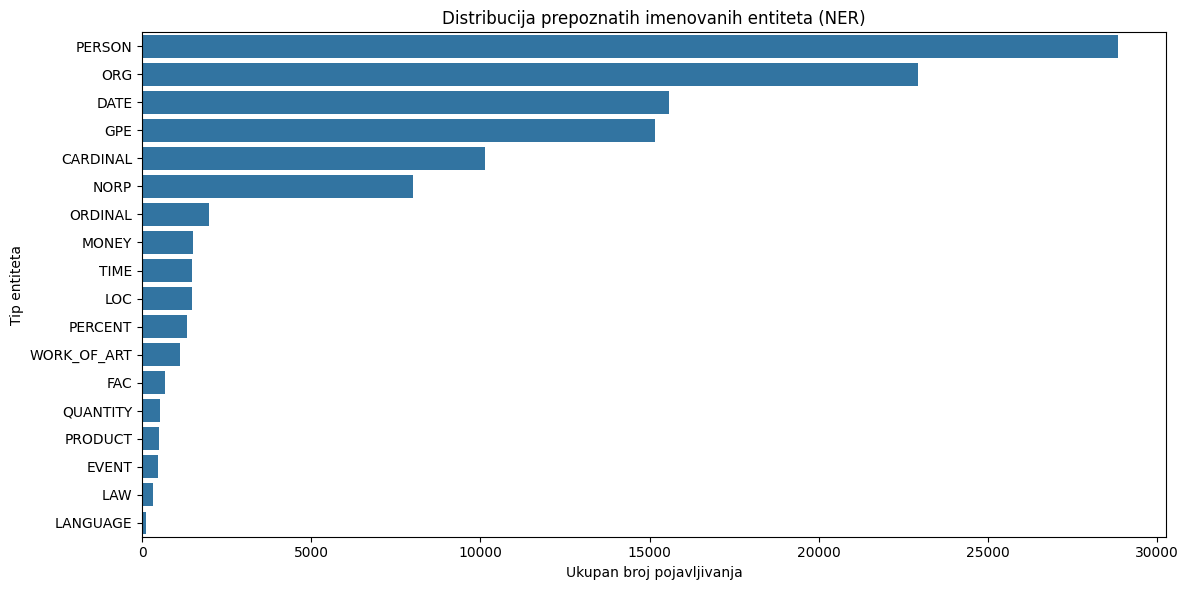

In [42]:
# BROJ ENTITETA PO TIPU
entity_counts = Counter(all_entity_types)
df_ner_counts = pd.DataFrame(entity_counts.items(), columns=['Tip entiteta', 'Broj pojavljivanja']).sort_values(by='Broj pojavljivanja', ascending=False)

print("\nBROJ ENTITETA PO TIPU")
print(df_ner_counts.to_string(index=False))

# DISTRIBUCIJA ENTITETA
plt.figure(figsize=(12, 6))
sns.barplot(x='Broj pojavljivanja', y='Tip entiteta', data=df_ner_counts)
plt.title('Distribucija prepoznatih imenovanih entiteta (NER)')
plt.xlabel('Ukupan broj pojavljivanja')
plt.ylabel('Tip entiteta')
plt.tight_layout()
plt.show()

In [43]:
# Dodatni uvid: Top 5 najčešćih konkretnih entiteta za nekoliko glavnih tipova
print("\nTOP 5 NAJČEŠĆIH KONKRETNIH ENTITETA PO KATEGORIJAMA")
entity_text_counts = Counter(all_entity_texts)

for target_type in ['PERSON', 'ORG', 'GPE', 'DATE']:
    print(f"\nTip: {target_type}")
    filtered_ents = {k[0]: v for k, v in entity_text_counts.items() if k[1] == target_type}
    top_ents = Counter(filtered_ents).most_common(5)
    for ent_text, count in top_ents:
        print(f"  - {ent_text}: {count} puta")


TOP 5 NAJČEŠĆIH KONKRETNIH ENTITETA PO KATEGORIJAMA

Tip: PERSON
  - Trump: 1587 puta
  - Clinton: 936 puta
  - Obama: 766 puta
  - Donald Trump: 603 puta
  - Hillary Clinton: 352 puta

Tip: ORG
  - Trump: 2329 puta
  - FBI: 304 puta
  - GOP: 295 puta
  - House: 293 puta
  - CNN: 293 puta

Tip: GPE
  - US: 653 puta
  - the United States: 538 puta
  - America: 484 puta
  - Russia: 430 puta
  - Washington: 380 puta

Tip: DATE
  - Tuesday: 402 puta
  - Wednesday: 378 puta
  - today: 341 puta
  - Friday: 305 puta
  - Thursday: 292 puta


3. RULE-BASED MATCHING

In [44]:
from spacy.matcher import Matcher

matcher = Matcher(nlp.vocab)

# Tržišne promene
glagoli_pada = ["dropped", "declined", "plunged", "slumping", "decreased", "fell", "sagged", "dived"]
glagoli_rasta = ["rose", "increased", "gained", "skyrocketed", "surpassed", "jumped", "soared"]
finansijski_pojmovi = ["shares", "stocks", "sales", "prices", "investment", "profit", "value", "pound", "pounds", "dollars"]

market_pattern_flexible_num = [
    {"LOWER": {"IN": glagoli_pada + glagoli_rasta}},
    {"IS_ALPHA": True, "OP": "*"},
    {"LIKE_NUM": True}
]

market_pattern_subject_verb = [
    {"LOWER": {"IN": finansijski_pojmovi}},
    {"OP": "*"},
    {"LOWER": {"IN": glagoli_pada + glagoli_rasta}}
]

market_pattern_currency = [
    {"LIKE_NUM": True},
    {"LOWER": {"IN": finansijski_pojmovi + ["percent", "percentage", "billion", "million"]}}
]

matcher.add("MARKET_MOVEMENT", [
    market_pattern_flexible_num,
    market_pattern_subject_verb,
    market_pattern_currency
])

# Vremenske odrednice
date_pattern = [
    {"LOWER": {"IN": ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday",
                      "september", "october", "november", "december", "january", "february", "august"]}},
    {"LOWER": {"IN": ["night", "morning", "afternoon", "evening"]}, "OP": "?"},
    {"LIKE_NUM": True, "OP": "?"}
]
matcher.add("NEWS_DATE", [date_pattern])

# Poslovne funkcije/titule
position_pattern = [
    {"LOWER": {"IN": ["chief", "press", "police", "national", "case"]}},
    {"LOWER": {"IN": ["executive", "secretary", "officer", "security", "manager"]}}
]

matcher.add("OFFICIAL_POSITION", [position_pattern])

matches_found = {"MARKET_MOVEMENT": 0, "NEWS_DATE": 0, "OFFICIAL_POSITION": 0}

In [45]:
for idx, text in enumerate(df['text']):
    if isinstance(text, str):
        doc = nlp(text)
        matches = matcher(doc)

        for match_id, start, end in matches:
            string_id = nlp.vocab.strings[match_id]
            matches_found[string_id] += 1

            #if sum(matches_found.values()) <= 15:
                #print(f"Vest #{idx} | Pravilo: {string_id:<18} | Pronađeni tekst: '{doc[start:end].text}'")

print("\nSTATISTIKA PRONAĐENIH REZULTATA")
for k, v in matches_found.items():
    print(f"Pravilo '{k}': pronađeno {v} puta.")


STATISTIKA PRONAĐENIH REZULTATA
Pravilo 'MARKET_MOVEMENT': pronađeno 3153 puta.
Pravilo 'NEWS_DATE': pronađeno 4462 puta.
Pravilo 'OFFICIAL_POSITION': pronađeno 292 puta.


4. BAG OF WORDS / N-Grams

In [46]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

df['cleaned_text'] = df['cleaned_text'].fillna('')

cv_unigram = CountVectorizer(ngram_range=(1, 1))
bow_unigrams = cv_unigram.fit_transform(df['cleaned_text'])

sum_words = bow_unigrams.sum(axis=0)
words_freq = [(word, sum_words[0, idx]) for word, idx in cv_unigram.vocabulary_.items()]
words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

df_top10_words = pd.DataFrame(words_freq[:10], columns=['Reč', 'Frekvencija'])

In [47]:
cv_bigram = CountVectorizer(ngram_range=(2, 2))
bow_bigrams = cv_bigram.fit_transform(df['cleaned_text'])

sum_bigrams = bow_bigrams.sum(axis=0)
bigrams_freq = [(bigram, sum_bigrams[0, idx]) for bigram, idx in cv_bigram.vocabulary_.items()]
bigrams_freq = sorted(bigrams_freq, key=lambda x: x[1], reverse=True)

df_top10_bigrams = pd.DataFrame(bigrams_freq[:10], columns=['N-gram (Bigram)', 'Frekvencija'])

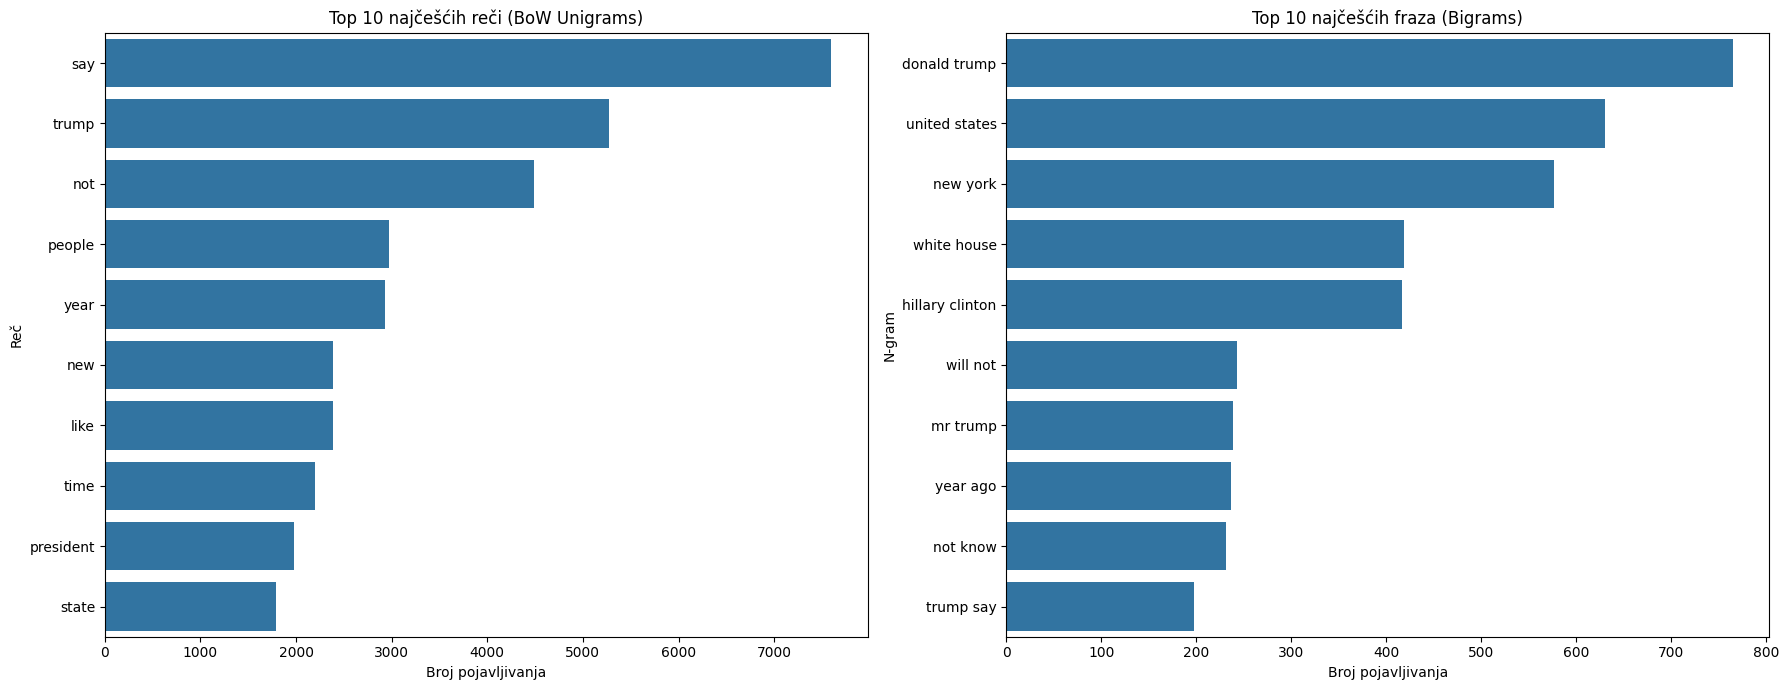

In [48]:
# Vizuelizacija

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(x='Frekvencija', y='Reč', data=df_top10_words, ax=axes[0])
axes[0].set_title('Top 10 najčešćih reči (BoW Unigrams)')
axes[0].set_xlabel('Broj pojavljivanja')
axes[0].set_ylabel('Reč')

sns.barplot(x='Frekvencija', y='N-gram (Bigram)', data=df_top10_bigrams, ax=axes[1])
axes[1].set_title('Top 10 najčešćih fraza (Bigrams)')
axes[1].set_xlabel('Broj pojavljivanja')
axes[1].set_ylabel('N-gram')

plt.tight_layout()
plt.show()

5. WORD SIMILARITY

In [49]:
!python -m spacy download en_core_web_md

import spacy
import pandas as pd
nlp_md = spacy.load("en_core_web_md")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 24.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [50]:
rec_1 = nlp_md.vocab["shares"]
rec_2 = nlp_md.vocab["stocks"]
rec_3 = nlp_md.vocab["police"]

slicnost_finansije = rec_1.similarity(rec_2)
slicnost_razlicito = rec_1.similarity(rec_3)

print(f"Sličnost između '{rec_1.text}' i '{rec_2.text}': {slicnost_finansije:.4f} (Visoka sličnost - isti domen)")
print(f"Sličnost između '{rec_1.text}' i '{rec_3.text}': {slicnost_razlicito:.4f} (Niska sličnost - različit domen)")

Sličnost između 'shares' i 'stocks': 0.4623 (Visoka sličnost - isti domen)
Sličnost između 'shares' i 'police': 0.0521 (Niska sličnost - različit domen)


In [51]:
rečenica_A = nlp_md(preprocess_text("Trump assails Nordstrom for dropping Ivanka's clothing line."))
rečenica_B = nlp_md(preprocess_text("The president lashed out at the department store chain over business decisions."))
rečenica_C = nlp_md(preprocess_text("A police officer fatally shot a man during a traffic stop in Minnesota."))

slicnost_AB = rečenica_A.similarity(rečenica_B)
slicnost_AC = rečenica_A.similarity(rečenica_C)

print(f"Sličnost (A <-> B): {slicnost_AB:.4f} (Model prepoznaje da obe govore o Trump-ovom napadu na biznis/prodavnice)")
print(f"Sličnost (A <-> C): {slicnost_AC:.4f} (Niža sličnost - rečenica C govori o drugoj temi)")

Sličnost (A <-> B): 0.4716 (Model prepoznaje da obe govore o Trump-ovom napadu na biznis/prodavnice)
Sličnost (A <-> C): 0.2927 (Niža sličnost - rečenica C govori o drugoj temi)


# **Zaključi**

U analiziranom setu vesti apsolutno dominiraju američka unutrašnja politika, geopolitika i političke kampanje. To se jasno vidi kroz preklapanje najfrekventnijih reči i entiteta. Teme su fokusirane na predsedničke izbore u SAD-u, odnose sa stranim silama (poput Rusije) i rad ključnih državnih i medijskih institucija (FBI, GOP, CNN).


---


Na osnovu ekstrakcije imenovanih entiteta (NER), dobili smo sledeće egzaktne podatke o liderima u svojim kategorijama:

Osobe (PERSON): Političke figure ubedljivo dominiraju, pri čemu je Donald Trump (zbirno kroz Trump sa 1587 i Donald Trump sa 603 pojavljivanja) najzastupljenija ličnost, a prate ga Clinton (936 puta) i Obama (766 puta).

Organizacije (ORG): Entitet Trump se ovde pojavljuje čak 2329 puta (što implicira kontekste poput Trump administration ili Trump Organization). Od institucija, najčešći su FBI (304 puta), GOP (295 puta), House (Prestavnički dom - 293 puta) i medijska kuća CNN (293 puta).

Geopolitički entiteti (GPE): Očekivano, najčešće se pominju SAD (kroz US - 653, the United States - 538 i America - 484 puta), dok je na spoljnopolitičkom planu najzastupljenija Rusija (Russia - 430 puta), kao i politički centar moći Vašington (Washington - 380 puta).